In [1]:
import sys, os
sys.path.append(os.path.abspath(".."))
import pandas as pd
from src.utils import *
from src.features import TARGET, preparar_target

In [2]:
df = pd.read_csv("../data/term_deposit.csv")
df[TARGET] = preparar_target(df[TARGET])   # yes/no -> 1/0
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,subscribed
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0


In [3]:
resumen_datos(df)

Shape: (41188, 21) | Duplicados: 12


,tipo,n_nulos,pct_nulos,n_unicos,ejemplo
age,int64,0,0.0,78,56
job,str,0,0.0,12,housemaid
marital,str,0,0.0,4,married
education,str,0,0.0,8,basic.4y
default,str,0,0.0,3,no
housing,str,0,0.0,3,no
loan,str,0,0.0,3,no
contact,str,0,0.0,2,telephone
month,str,0,0.0,10,may
day_of_week,str,0,0.0,5,mon


In [4]:
distribucion_target(df[TARGET])

Ratio de desbalance (mayoritaria/minoritaria): 7.88 : 1


,n,pct
subscribed,,
0,36548,88.73
1,4640,11.27


In [5]:
detectar_columnas_problema(df)
num_cols, cat_cols = tipos_variables(df, TARGET)

constantes: []
tipo_id: []
muchos_nulos: []
Numéricas (10): ['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
Categóricas (10): ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']


In [6]:
print("pdays = 999 (nunca contactado):", round((df["pdays"] == 999).mean() * 100, 2), "%")
for c in cat_cols:
    pct = (df[c] == "unknown").mean() * 100
    if pct > 0:
        print(f"{c}: {pct:.1f}% 'unknown'")

pdays = 999 (nunca contactado): 96.32 %
job: 0.8% 'unknown'
marital: 0.2% 'unknown'
education: 4.2% 'unknown'
default: 20.9% 'unknown'
housing: 2.4% 'unknown'
loan: 2.4% 'unknown'


In [7]:
resumen_atipicos(df, num_cols)

,variable,lim_inf,lim_sup,n_bajo,n_alto,pct_atipicos,nota
0,previous,0.0000,0.0000,0,5625,13.66,IQR=0: no se aplica capping
1,duration,-223.5000,644.5000,0,2963,7.19,
2,campaign,-2.0000,6.0000,0,2406,5.84,
3,pdays,999.0000,999.0000,1515,0,3.68,IQR=0: no se aplica capping
4,age,9.5000,69.5000,0,469,1.14,
5,cons.conf.idx,-52.1500,-26.9500,0,447,1.09,
6,emp.var.rate,-6.6000,6.2000,0,0,0.00,
7,cons.price.idx,91.6965,95.3725,0,0,0.00,
8,euribor3m,-4.0815,10.3865,0,0,0.00,
9,nr.employed,4905.6000,5421.6000,0,0,0.00,


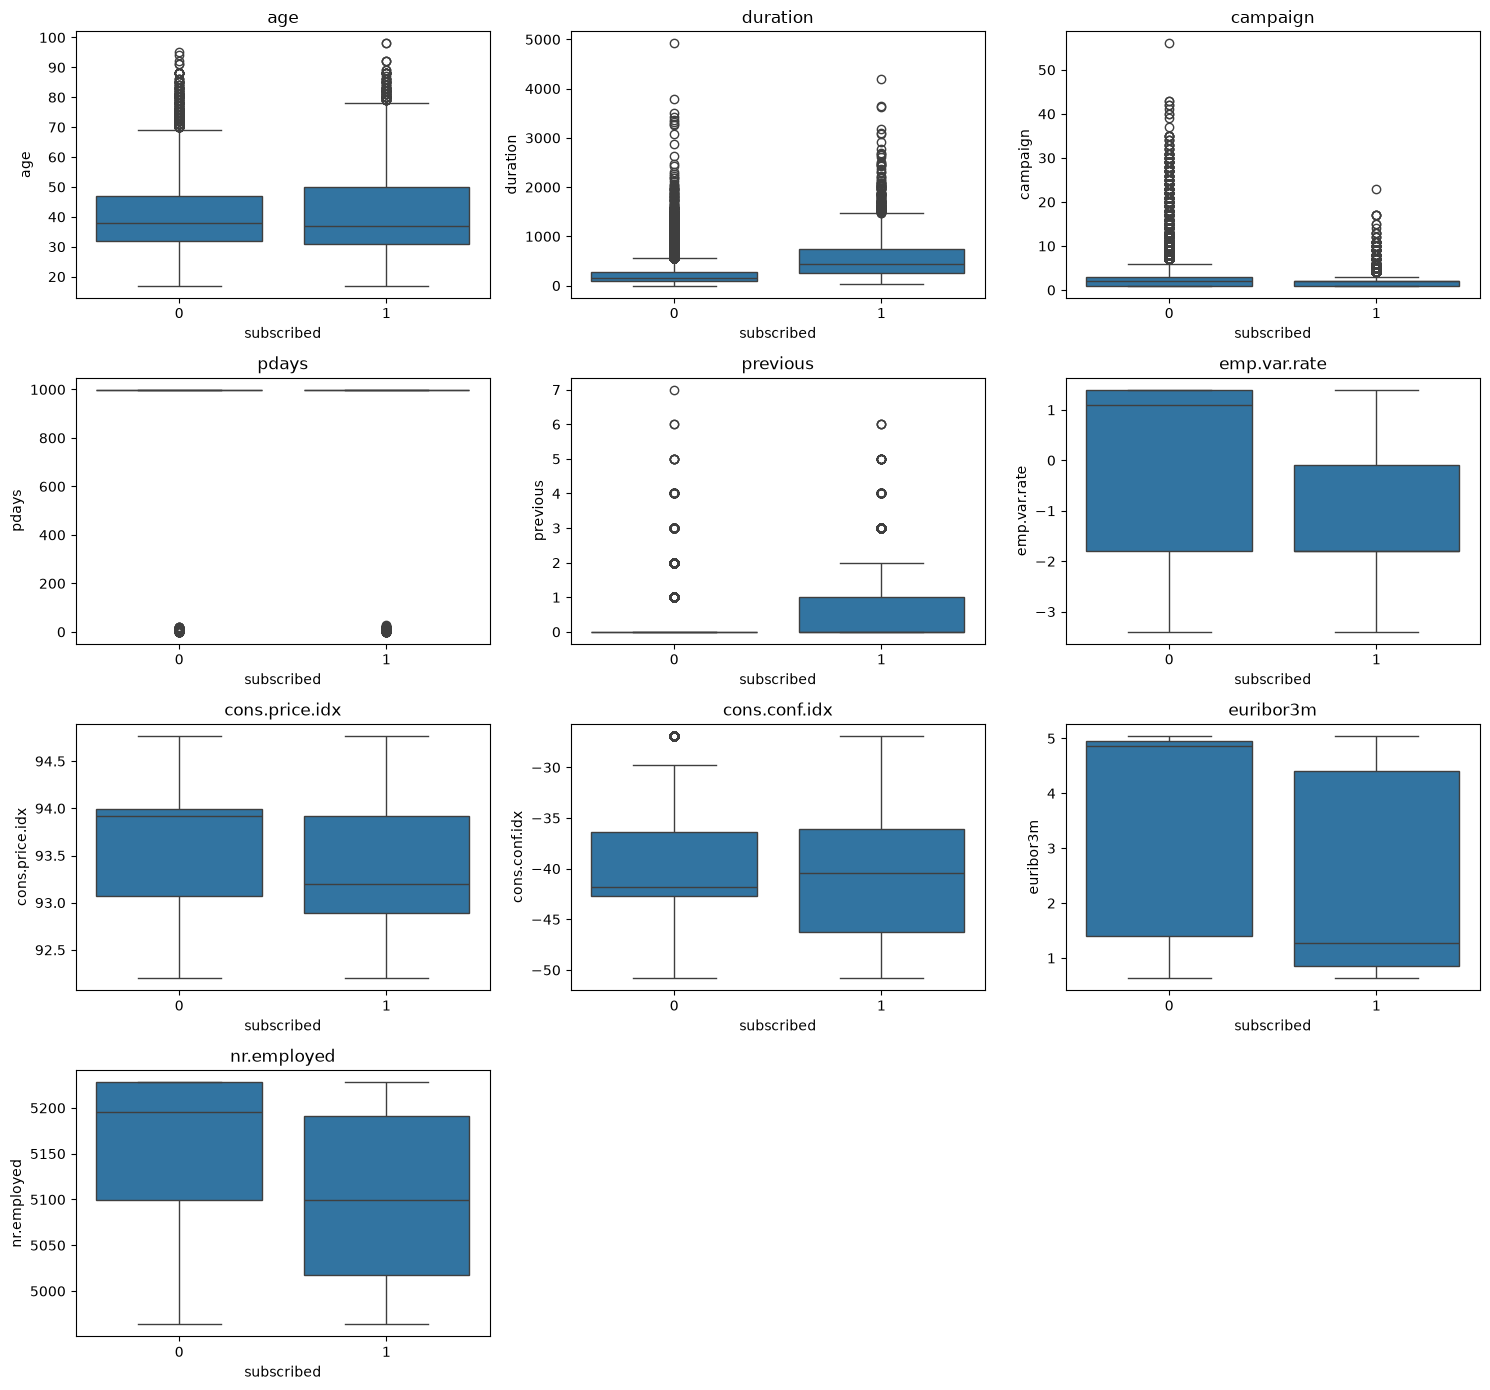

In [13]:
graficar_numericas_vs_target(df, num_cols, TARGET);

In [9]:
for c in cat_cols:
    display(tasa_target_por_categoria(df, c, TARGET))

,n,tasa_evento
job,,
student,875,0.314286
retired,1720,0.252326
unemployed,1014,0.142012
admin.,10422,0.129726
management,2924,0.112175
unknown,330,0.112121
technician,6743,0.108260
self-employed,1421,0.104856
housemaid,1060,0.100000


,n,tasa_evento
marital,,
unknown,80,0.150000
single,11568,0.140041
divorced,4612,0.103209
married,24928,0.101573


,n,tasa_evento
education,,
illiterate,18,0.222222
unknown,1731,0.145003
university.degree,12168,0.137245
professional.course,5243,0.113485
high.school,9515,0.108355
basic.4y,4176,0.102490
basic.6y,2292,0.082024
basic.9y,6045,0.078246


,n,tasa_evento
default,,
no,32588,0.12879
unknown,8597,0.05153
yes,3,0.00000


,n,tasa_evento
housing,,
yes,21576,0.116194
no,18622,0.108796
unknown,990,0.108081


,n,tasa_evento
loan,,
no,33950,0.113402
yes,6248,0.109315
unknown,990,0.108081


,n,tasa_evento
contact,,
cellular,26144,0.147376
telephone,15044,0.052313


,n,tasa_evento
month,,
mar,546,0.505495
dec,182,0.489011
sep,570,0.449123
oct,718,0.438719
apr,2632,0.204787
aug,6178,0.106021
jun,5318,0.105115
nov,4101,0.101439
jul,7174,0.090466


,n,tasa_evento
day_of_week,,
thu,8623,0.121188
tue,8090,0.117800
wed,8134,0.116671
fri,7827,0.108087
mon,8514,0.099483


,n,tasa_evento
poutcome,,
success,1373,0.651129
failure,4252,0.142286
nonexistent,35563,0.088322


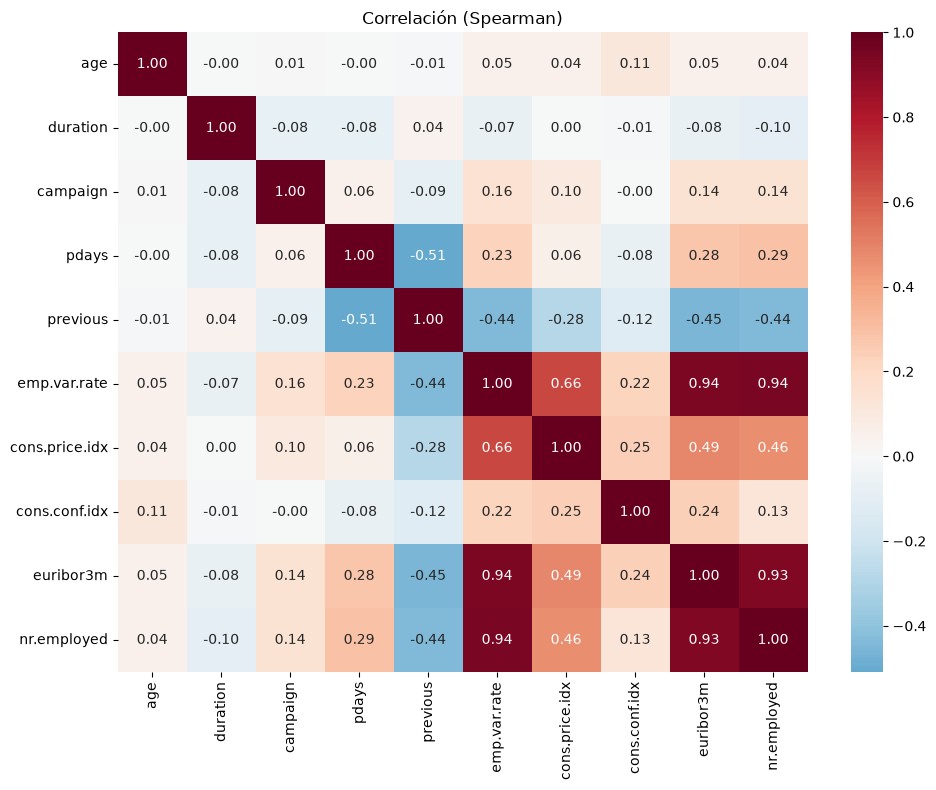

In [12]:
graficar_correlacion(df, num_cols);

## Conclusiones del EDA
- **Calidad:** 41 188 filas, 21 columnas, sin nulos explícitos. 12 duplicados, que se eliminan antes del split.
- **Desbalance:** 11.27 % de "yes" (ratio 7.88 : 1). Se tratará con pesos por clase; el accuracy no sirve como métrica.
- **Leakage:** `duration` solo se conoce después de la llamada; se excluye del modelo.
- **pdays:** 96.3 % vale 999, un código de "nunca contactado". Se convierte a nulo y se crea `contactado_antes`.
- **"unknown":** se mantiene como categoría porque tiene información (en `default`, "unknown" convierte 5.2 % contra 12.9 % de "no"). `default = yes` tiene solo 3 casos.
- **Atípicos:** se aplica capping IQR, no eliminación. Los mayores de 69.5 años convierten al 47 %: son atípicos reales y predictivos. `previous` y `pdays` tienen IQR = 0, así que no se recortan.
- **Variables con más poder:** `poutcome = success` (65 % de conversión), contacto por celular (14.7 % contra 5.2 %), estudiantes y jubilados, y los meses de marzo, septiembre, octubre y diciembre. `housing`, `loan` y `day_of_week` casi no discriminan.
- **Correlación:** `emp.var.rate`, `euribor3m` y `nr.employed` tienen correlación de 0.93 a 0.94. Afecta al logit (se filtra con correlación y VIF), no a los árboles.
- **Limitación:** las variables macro dependen de la fecha del contacto; sin año en los datos, el split es aleatorio y las métricas podrían ser optimistas.